# 02 · Patterns, Seasonality and Target Behaviour

**Goal:** find the time patterns and weather links that justify our features (lags, rolling means, calendar and weather variables).

In [1]:
import os
import sys

# Find the project folder (the one that contains config.py) and work from there
ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, "config.py")):
    ROOT = os.path.dirname(ROOT)
os.chdir(ROOT)
sys.path.append(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config

FIG = "reports/figures"
OUT = "data/GeneratedOutput/01.EDA"
os.makedirs(FIG, exist_ok=True)
os.makedirs(OUT, exist_ok=True)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

In [2]:
from data_loader import load_raw_data

raw = load_raw_data(config.RAW_FILE)
pm = raw["pm25"]

## 1. PM2.5 over time

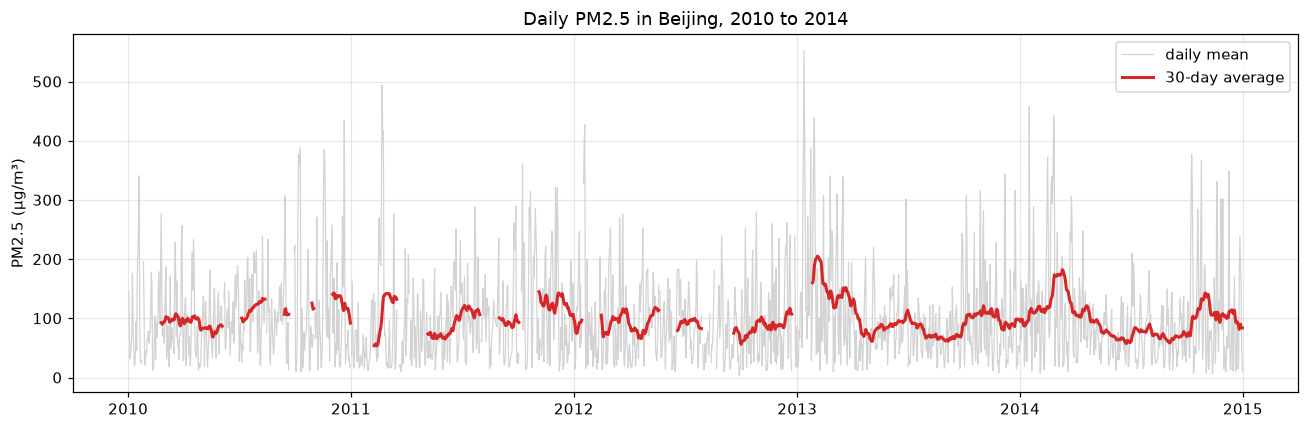

In [3]:
daily = pm.resample("D").mean()
monthly = pm.resample("MS").mean()
monthly.to_frame("mean_pm25").to_csv(f"{OUT}/03_monthly_pm25.csv")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily, color="lightgray", linewidth=0.8, label="daily mean")
ax.plot(daily.index, daily.rolling(30).mean(), color="tab:red", linewidth=2, label="30-day average")
ax.set_title("Daily PM2.5 in Beijing, 2010 to 2014")
ax.set_ylabel("PM2.5 (µg/m³)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG}/03_pm25_over_time.png")
plt.show()

## 2. Seasonality: hour of day, day of week, month

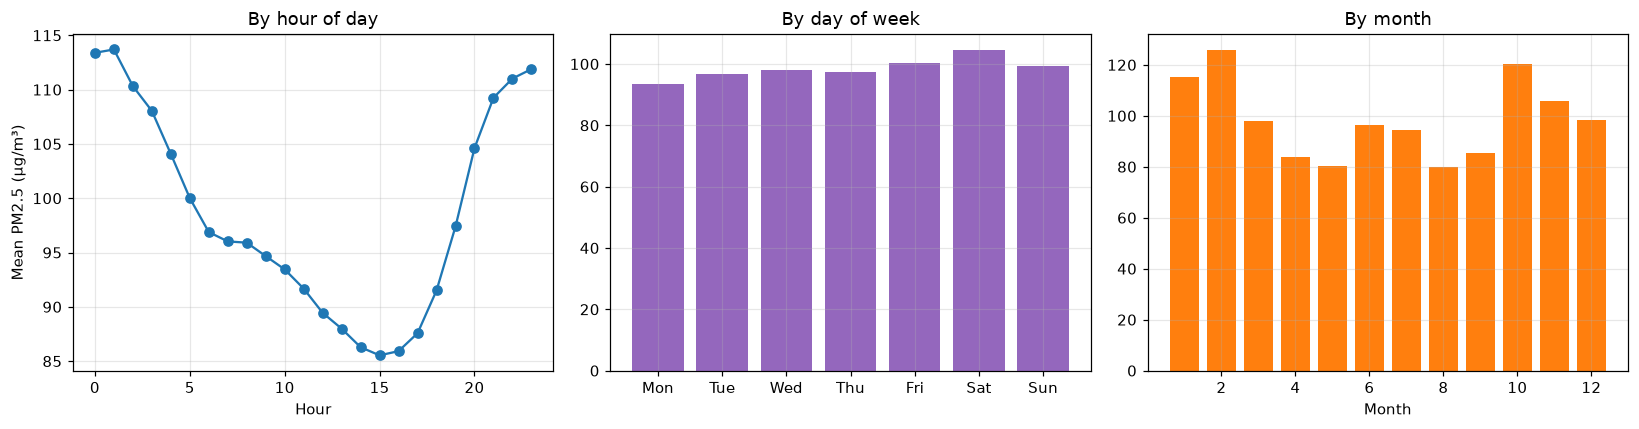

In [4]:
by_hour = pm.groupby(pm.index.hour).mean()
by_day = pm.groupby(pm.index.day_of_week).mean()
by_month = pm.groupby(pm.index.month).mean()

seasonality = pd.concat({"by_hour": by_hour, "by_day_of_week": by_day, "by_month": by_month}, axis=1).round(1)
seasonality.to_csv(f"{OUT}/04_seasonality.csv")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(by_hour.index, by_hour.values, marker="o")
axes[0].set_title("By hour of day")
axes[0].set_xlabel("Hour")
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], by_day.values, color="tab:purple")
axes[1].set_title("By day of week")
axes[2].bar(by_month.index, by_month.values, color="tab:orange")
axes[2].set_title("By month")
axes[2].set_xlabel("Month")
axes[0].set_ylabel("Mean PM2.5 (µg/m³)")
plt.tight_layout()
plt.savefig(f"{FIG}/04_seasonality.png")
plt.show()

PM2.5 is highest **at night** (about 113 µg/m³ around midnight) and lowest in the **afternoon** (about 86 at 15:00). It peaks in **winter heating months** (February about 126, October about 120). The day of the week matters much less.

This is why we add `hour`, `month` and their sin/cos versions as features.

## 3. Wind direction

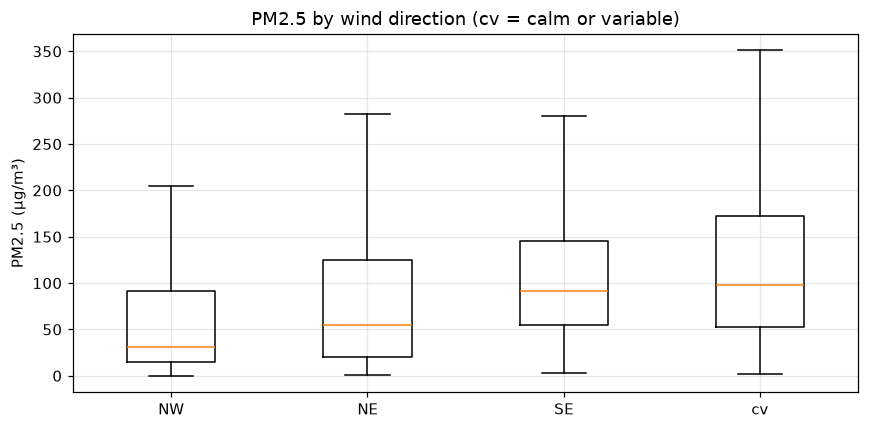

,mean,median,count
cbwd,,,
NE,90.2,55.0,4756
NW,70.1,31.0,13484
SE,110.8,91.0,14573
cv,126.2,98.0,8944


In [5]:
order = ["NW", "NE", "SE", "cv"]
groups = [raw.loc[raw["cbwd"] == w, "pm25"].dropna() for w in order]

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(groups, tick_labels=order, showfliers=False)
ax.set_title("PM2.5 by wind direction (cv = calm or variable)")
ax.set_ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.savefig(f"{FIG}/05_wind_direction.png")
plt.show()

raw.groupby("cbwd")["pm25"].agg(["mean", "median", "count"]).round(1)

Northwest wind brings clean air from the mountains (median PM2.5 is 31). Calm air lets pollution build up (median 98). So wind direction gets one-hot columns.

## 4. Correlation between PM2.5 and weather

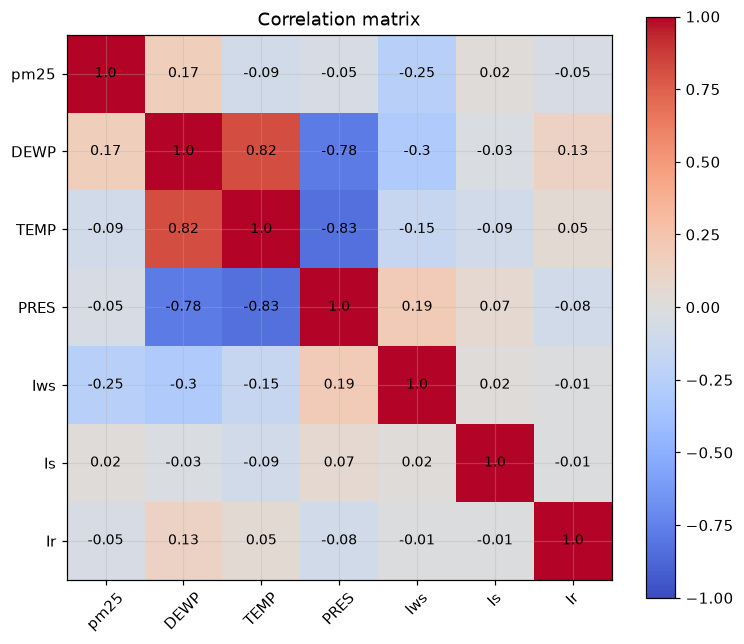

In [6]:
numeric = raw.drop(columns="cbwd")
corr = numeric.corr().round(2)
corr.to_csv(f"{OUT}/05_correlations.csv")

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=9)
fig.colorbar(image)
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.savefig(f"{FIG}/06_correlation_matrix.png")
plt.show()

No single weather variable is strongly linked to PM2.5 on its own. Wind speed (`Iws`, -0.25) and dew point (`DEWP`, 0.17) matter most. The links are non-linear and work together, which suits a tree model like XGBoost.

## 5. Autocorrelation: how long does PM2.5 'remember'?

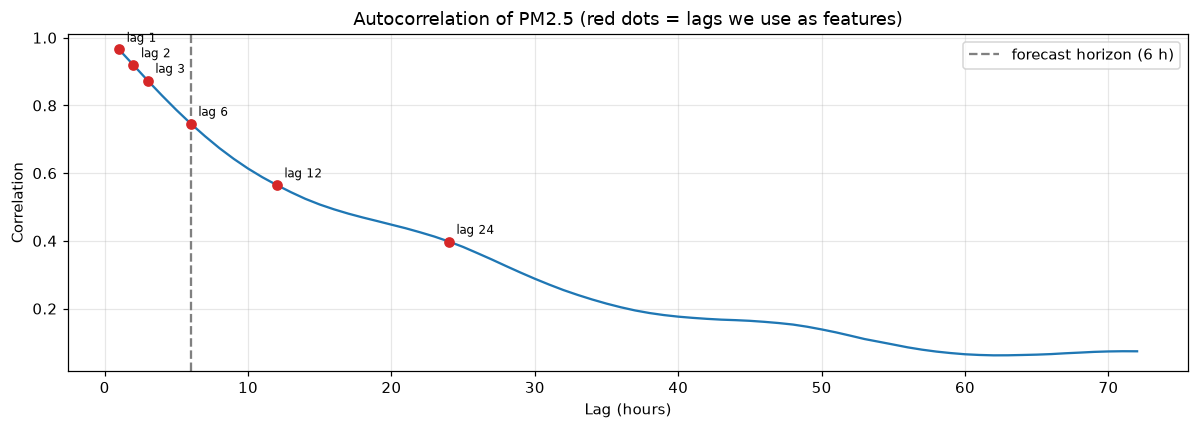

In [7]:
lags = range(1, 73)
acf = pd.Series([pm.autocorr(lag) for lag in lags], index=lags)
acf.to_frame("autocorrelation").to_csv(f"{OUT}/06_autocorrelation.csv")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(acf.index, acf.values, color="tab:blue")
for lag in config.LAGS:
    ax.scatter(lag, acf[lag], color="tab:red", zorder=3)
    ax.annotate(f"lag {lag}", (lag, acf[lag]), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.axvline(config.HORIZON, color="gray", linestyle="--", label="forecast horizon (6 h)")
ax.set_title("Autocorrelation of PM2.5 (red dots = lags we use as features)")
ax.set_xlabel("Lag (hours)")
ax.set_ylabel("Correlation")
ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG}/07_autocorrelation.png")
plt.show()

## Key findings

- PM2.5 is very **persistent**: the correlation with 1 hour ago is 0.97, with 6 hours ago 0.75, and with 24 hours ago 0.40. That is why persistence is a strong baseline.
- The memory fades after about 2 days (0.15 at 48 h), so lags up to 24 h plus 6 h and 24 h rolling means cover most of it.
- Clear **daily and yearly cycles** lead to calendar features. **Wind direction and speed** are the strongest weather signals.
- Yearly averages barely change (about 90 to 104 µg/m³), so the 2013 to 2014 test years are similar to the training years.